Import Required Libraries

In [90]:
import numpy as np
import pandas as pd
import datetime as dt
import matplotlib.pyplot as plt
import seaborn as sns
import folium
import geopandas as gpd
import matplotlib.colors as mcolors
import matplotlib.ticker as ticker
import plotly.express as px
import plotly.graph_objects as go
import datetime
from sklearn.cluster import KMeans
from matplotlib.font_manager import FontProperties
from IPython.display import HTML as html_print
from termcolor import colored
from scipy import stats
import warnings
import plotly.graph_objects as go
from plotly.subplots import make_subplots

warnings.filterwarnings('ignore', category=FutureWarning)

Adjust Row Column Settings

In [91]:
pd.set_option('display.max_columns', None)
#pd.set_option('display.max_rows', None)
pd.set_option('display.width', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

Loading the Data Set

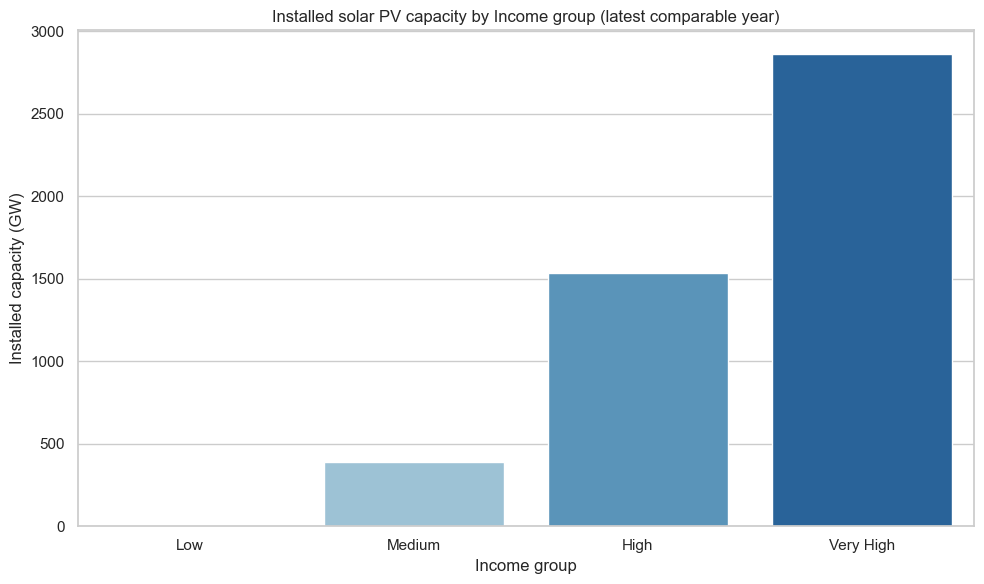

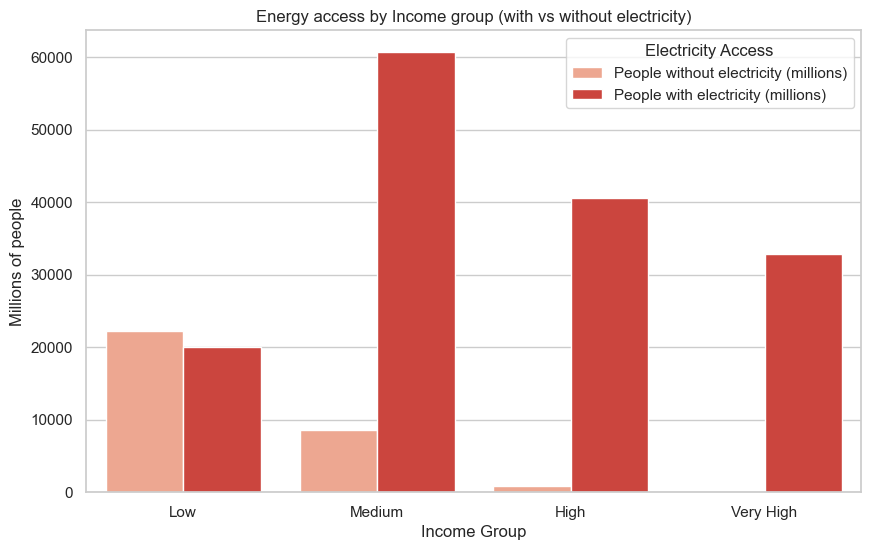

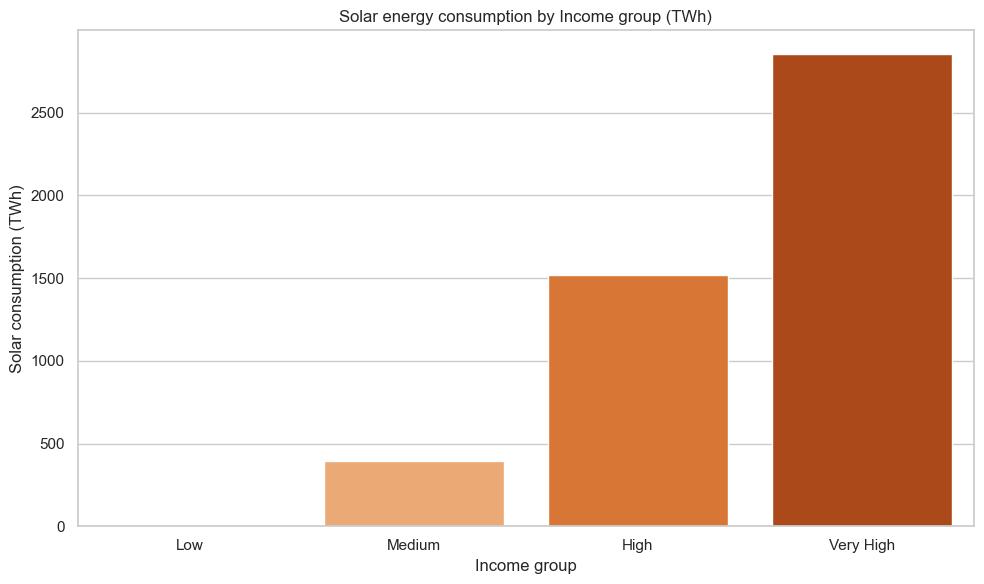

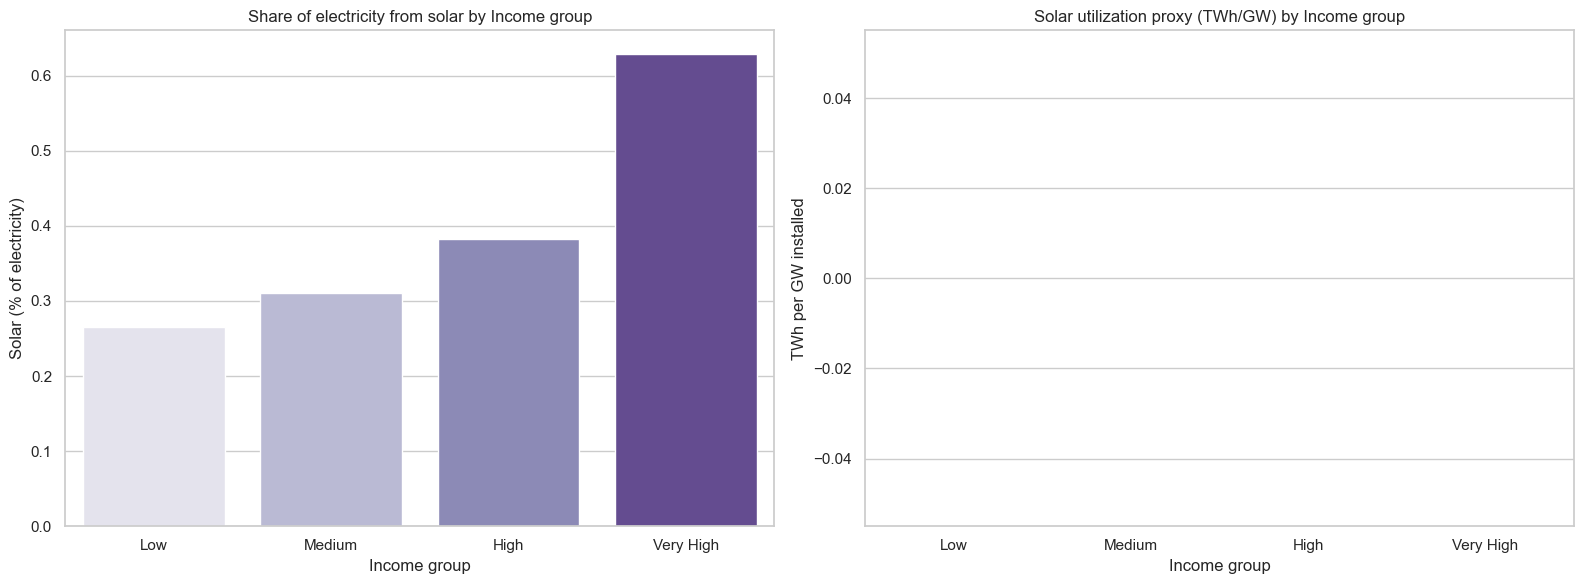

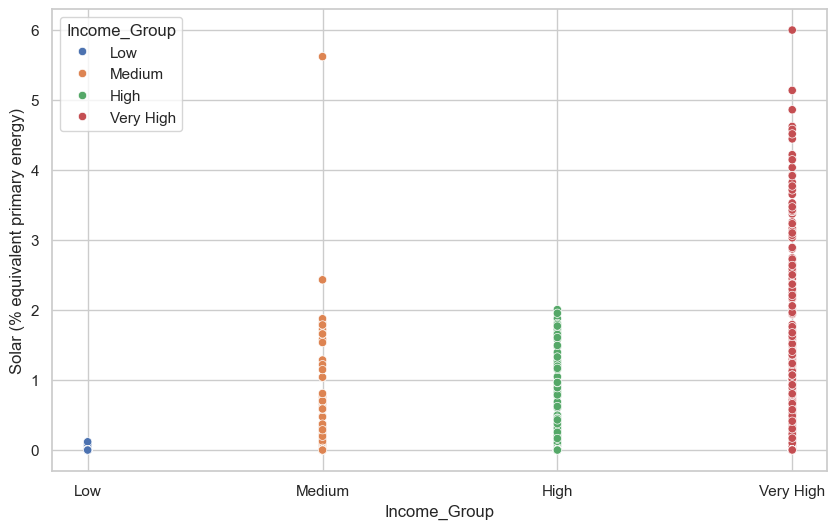

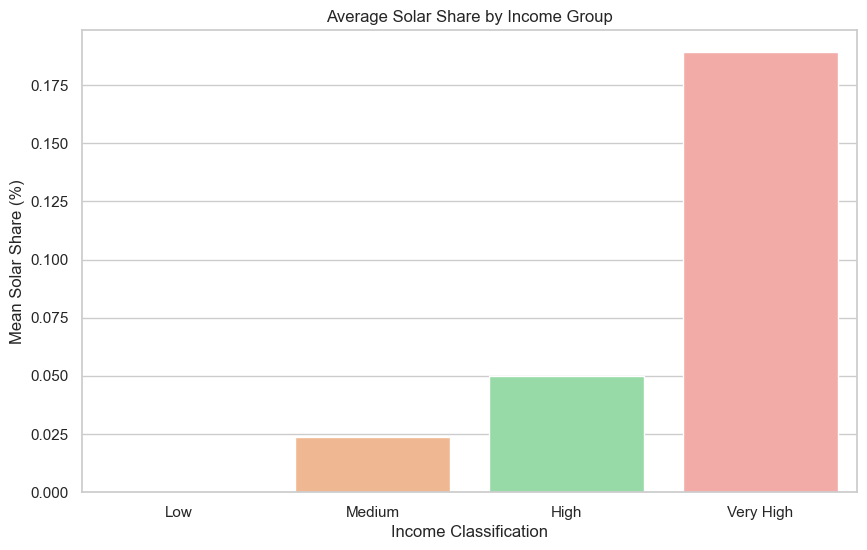

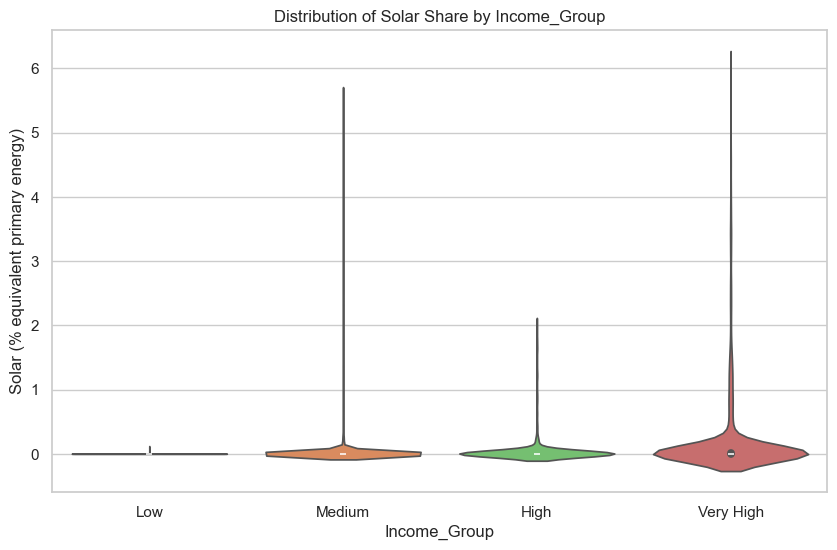

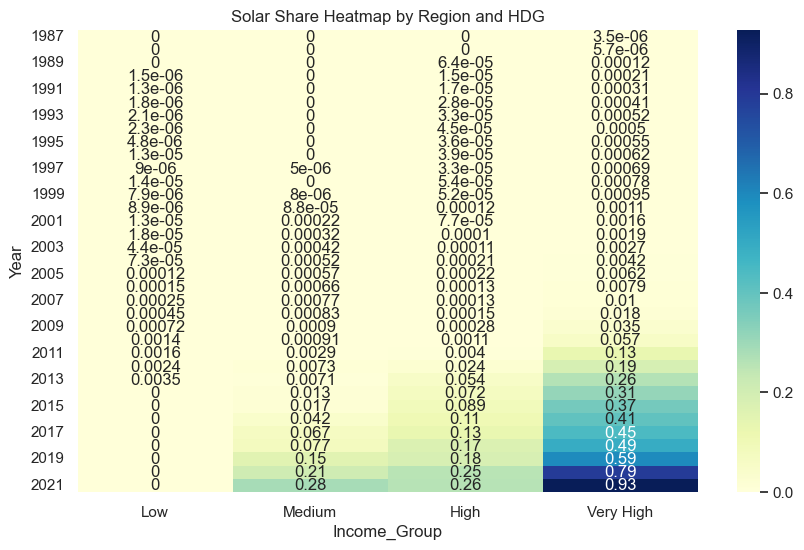

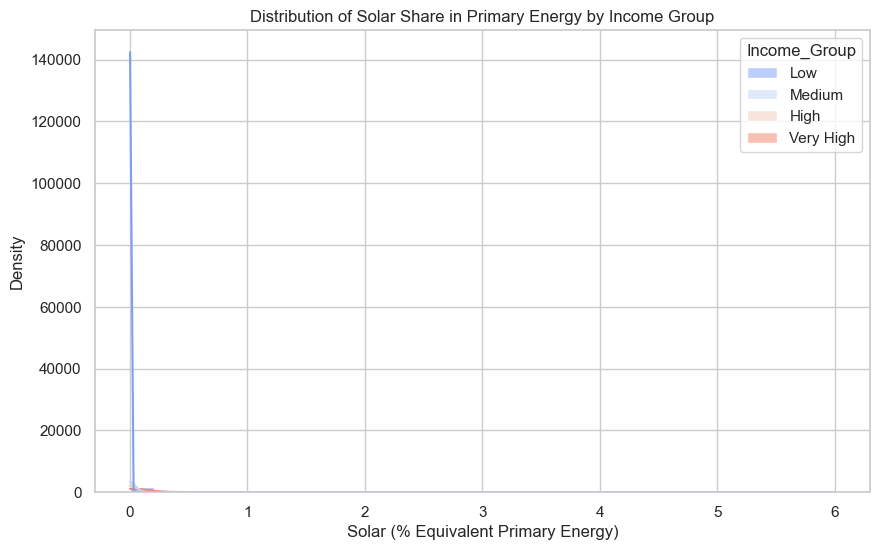

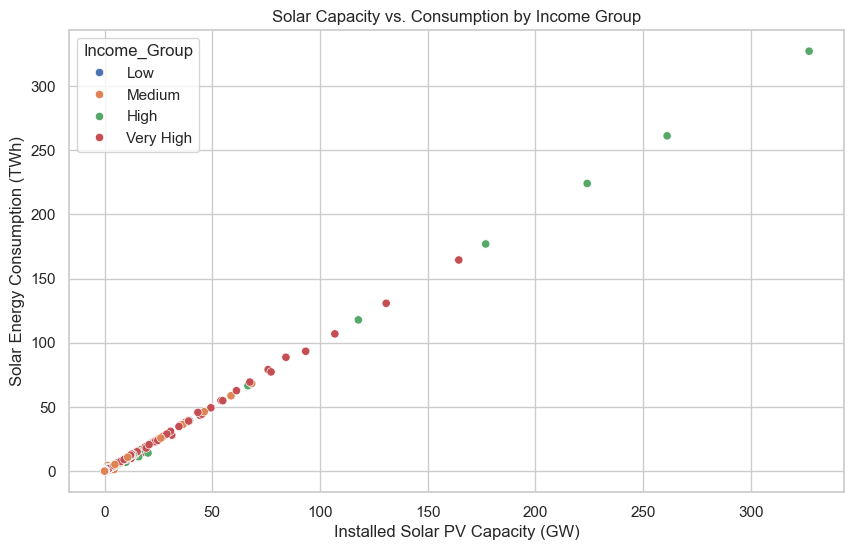

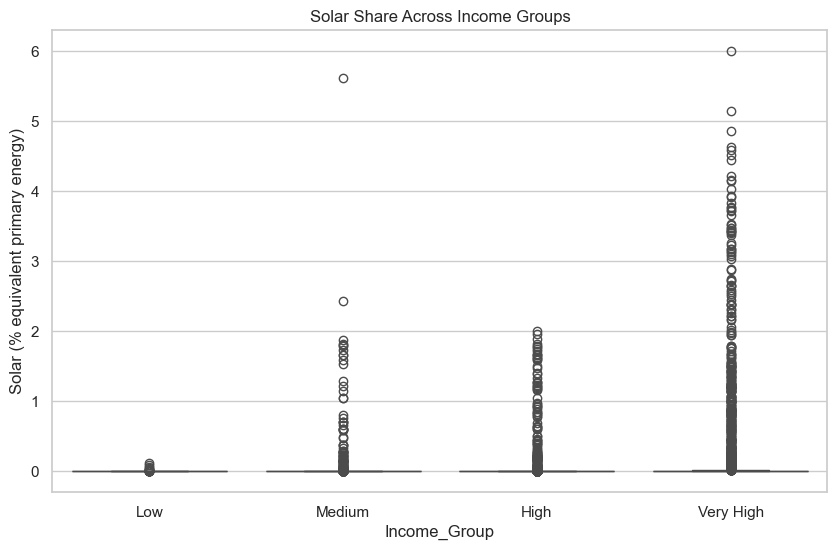

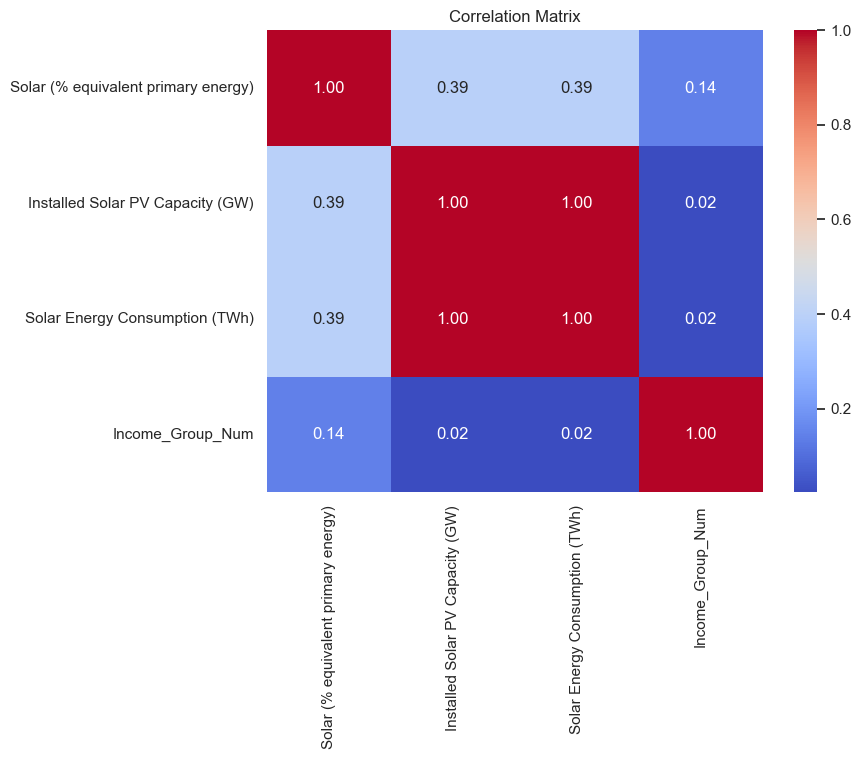

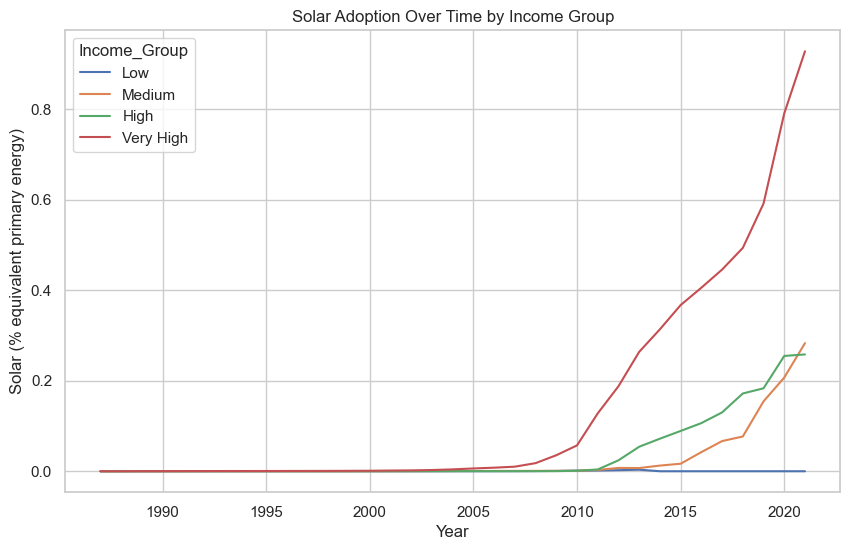

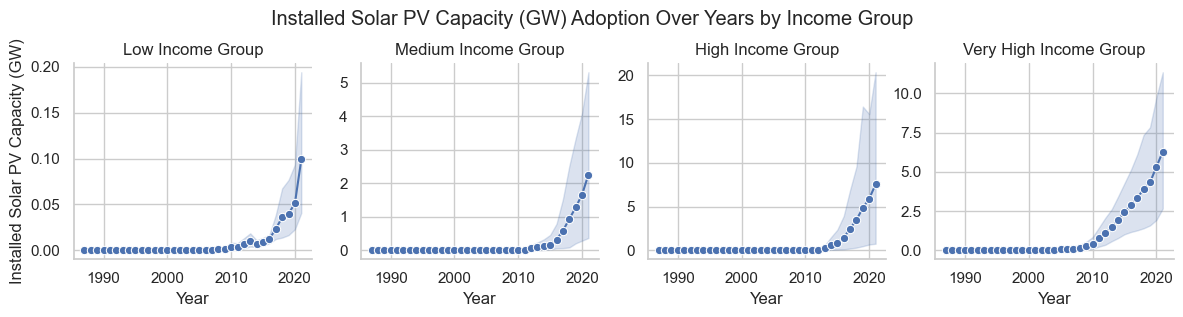

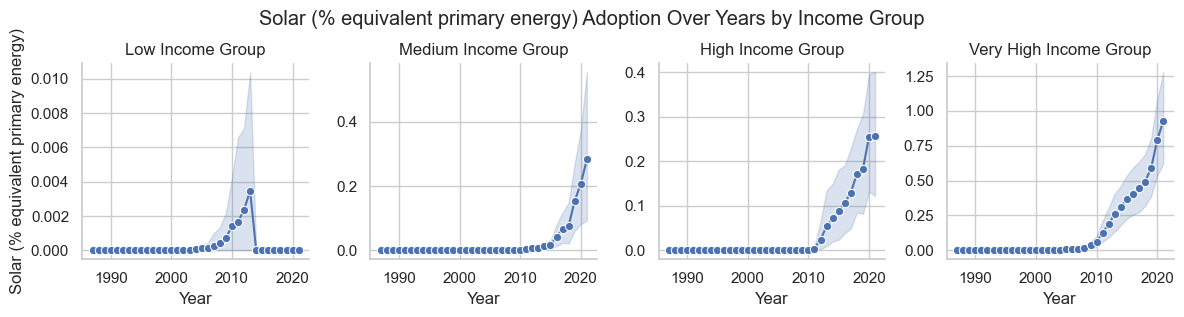

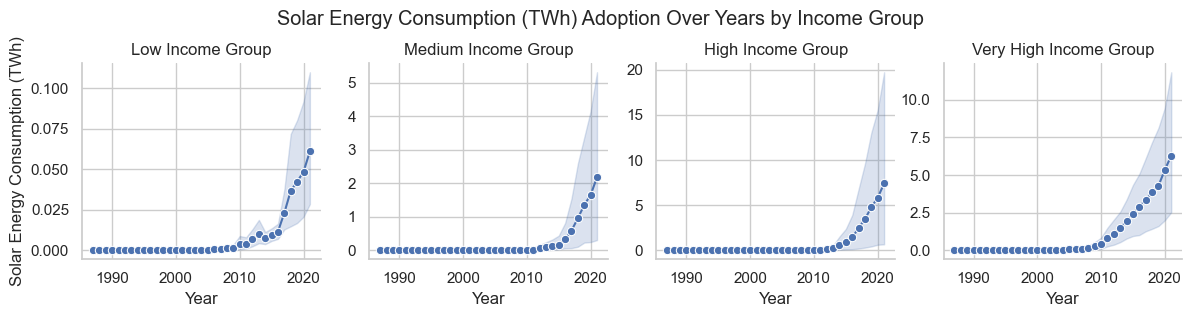

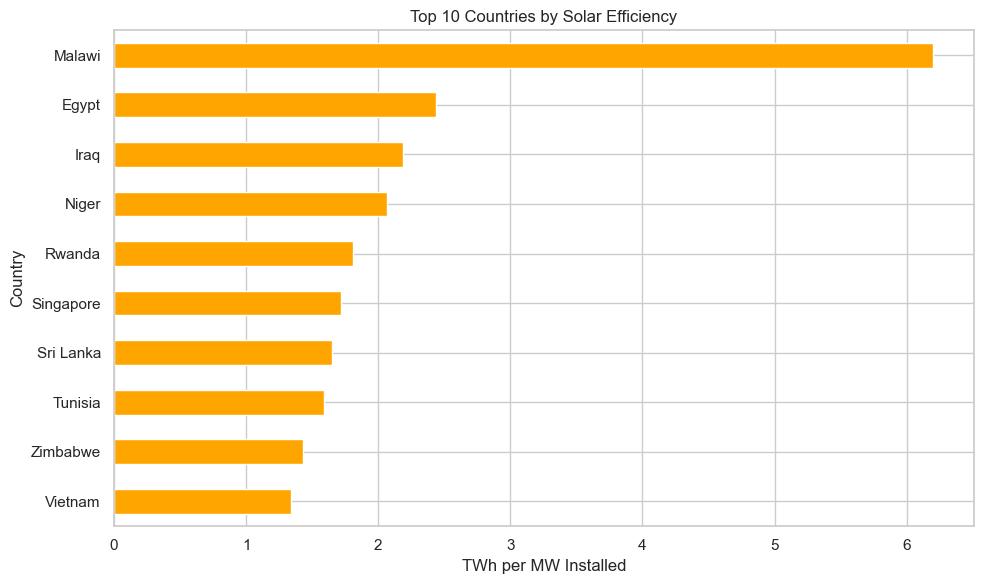

In [92]:
# Define the custom order for Income groups
income_group = ["Low", "Medium", "High", "Very High"]

# Drop rows with missing values in key columns before merge
# Income Groups using World Bank Income Groups dataset
df_income_group = pd.read_csv("data/world-bank-income-groups.csv")
df_income_group_clean = df_income_group.dropna(subset=["Entity", "Code","Year", "World Bank's income classification"])[["Entity","Code", "Year", "World Bank's income classification"]]
# Rename 'Entity' to 'Country' in the income group dataset
df_income_group_clean.rename(columns={"Entity": "Country"}, inplace=True)
df_income_group_clean.rename(columns={"World Bank's income classification":"Income_Group"}, inplace=True)
# Keep only years <= 2021
df_income_group_clean = df_income_group_clean[df_income_group_clean["Year"] <= 2021]

# Map long income group labels to shorter ones
mapping = {
    "Low-income countries": "Low",
    "Lower-middle-income countries": "Medium",
    "Upper-middle-income countries": "High",
    "High-income countries": "Very High"
}
df_income_group_clean["Income_Group"] = df_income_group_clean["Income_Group"].replace(mapping)


#Solar data
#% of total primary energy from solar — solar’s role in national energy mix
df_solar_share = pd.read_csv("data/14 solar-share-energy.csv")
df_solar_share_clean = df_solar_share.dropna(subset=["Code", "Year"])[["Code", "Year", "Solar (% equivalent primary energy)"]]
df_solar_share_clean["Solar (% equivalent primary energy)"] = df_solar_share_clean["Solar (% equivalent primary energy)"].fillna("0.00")

#Installed solar PV capacity — infrastructure readiness
df_installed_capacity = pd.read_csv("data/solar-energy-generation.csv")
df_installed_capacity_clean = df_installed_capacity.dropna(subset=["Code", "Year"])[["Code", "Year", "Electricity from solar - TWh"]]
df_installed_capacity_clean["Electricity from solar - TWh"] = df_installed_capacity_clean["Electricity from solar - TWh"].fillna("0.00")
df_installed_capacity_clean.rename(columns={"Electricity from solar - TWh": "Installed Solar PV Capacity (GW)"}, inplace=True)

#Total solar energy consumed — absolute solar uptake
df_solar_energy_consumption = pd.read_csv("data/12 solar-energy-consumption.csv")
df_solar_energy_consumption_clean = df_solar_energy_consumption.dropna(subset=["Code", "Year"])[["Code", "Year", "Electricity from solar (TWh)"]]
df_solar_energy_consumption_clean["Electricity from solar (TWh)"] = df_solar_energy_consumption_clean["Electricity from solar (TWh)"].fillna("0.00")
df_solar_energy_consumption_clean.rename(columns={"Electricity from solar (TWh)": "Solar Energy Consumption (TWh)"}, inplace=True)

#% of electricity from solar — grid-level solar penetration or Grid capacity
df_solar_electricity_share = pd.read_csv("data/15 share-electricity-solar.csv")
df_solar_electricity_share_clean = df_solar_electricity_share.dropna(subset=["Code", "Year"])[["Code", "Year", "Solar (% electricity)"]]
df_solar_electricity_share_clean["Solar (% electricity)"] = df_solar_electricity_share_clean["Solar (% electricity)"].fillna("0.00")

#Energy Poverty from - https://ourworldindata.org/number-without-electricity
df_energy_poverty = pd.read_csv("data/energy-poverty.csv")
df_energy_poverty_clean = df_energy_poverty.dropna(subset=["Code", "Year"])[["Code", "Year","Access to electricity (number of people with access)","Access to electricity (number of people without access)"]]
df_energy_poverty_clean["Access to electricity (number of people with access)"] = df_energy_poverty_clean["Access to electricity (number of people with access)"].fillna("0.00")
df_energy_poverty_clean["Access to electricity (number of people without access)"] = df_energy_poverty_clean["Access to electricity (number of people without access)"].fillna("0.00")
df_energy_poverty_clean.rename(columns={"Access to electricity (number of people without access)": "Number of people without electricity"}, inplace=True)
df_energy_poverty_clean.rename(columns={"Access to electricity (number of people with access)": "Number of people with electricity"}, inplace=True)

#Continents grouping dataset
df_regions = pd.read_csv("data/continents.csv")  
df_regions = df_regions.rename(columns={"alpha-3": "Code", "region": "Region"})

#Populationdataset
df_pop = pd.read_csv("data/population.csv")
df_pop_clean = df_pop.dropna(subset=["Code", "Year"])[["Code", "Year", "Population (historical)"]]
df_pop_clean["Population (historical)"] = df_pop_clean["Population (historical)"].fillna("0.00")
df_pop_clean.rename(columns={"Population (historical)": "Population"}, inplace=True)

df_income_group_clean["Code"] = df_income_group_clean["Code"].str.strip().str.upper()
df_energy_poverty_clean["Code"] = df_energy_poverty_clean["Code"].str.strip().str.upper()
energy_poverty_merged = pd.merge(df_income_group_clean,df_energy_poverty_clean, on=["Code", "Year"], how="inner")
energy_poverty_merged.to_csv('outputs/energy_poverty_merged.csv', index=False)

# Merge on Country code and year
# Start with solar share and Income Group
merged_df = pd.merge(df_income_group_clean,df_solar_share_clean, on=["Code", "Year"], how="left")

# Add installed capacity
merged_df = merged_df.merge(df_installed_capacity_clean, on=["Code", "Year"], how="left")

# Add solar consumption
merged_df = merged_df.merge(df_solar_energy_consumption_clean, on=["Code", "Year"], how="left")

# Add solar electricity share
merged_df = merged_df.merge(df_solar_electricity_share_clean, on=["Code", "Year"], how="left")

#Add energy poverty showing people with and without electricity
merged_df = merged_df.merge(df_energy_poverty_clean, on=["Code", "Year"], how="left")

#Add regions grouping data
merged_df = merged_df.merge(df_regions, on="Code", how="left")
merged_df["Region"] = merged_df["Region"].fillna("Unassigned")

#Add population data
merged_df = merged_df.merge(df_pop_clean, on=["Code", "Year"], how="left")

# Optional: drop any remaining NaNs post-merge
merged_df = merged_df.fillna(0)
#merged_df = merged_df.dropna()

# Preview
merged_df.head()
merged_df.to_csv('outputs/output.csv', index=False)

# Convert Income_Group to ordered categorical
merged_df["Income_Group"] = pd.Categorical(
    merged_df["Income_Group"],
    categories=income_group,
    ordered=True
)
"""
# Strategy: use the most recent year where both Installed Capacity and Solar Consumption are available per country.
def pick_latest_consistent(df, cols_required):
    df_sorted = df.sort_values(["Code","Year"])
    # For each country, keep only rows with all required cols present, then pick the latest year
    mask = df_sorted[cols_required].notna().all(axis=1)
    df_ok = df_sorted[mask]
    latest = df_ok.sort_values(["Code","Year"]).groupby("Code").tail(1)
    return latest

cols_req = ["Installed Solar PV Capacity (GW)", "Solar Energy Consumption (TWh)"]
#latest = pick_latest_consistent(merged_df, cols_req)


# Attach latest energy poverty data (match closest year within a tolerance)
def merge_closest_year(left, right, on_code="Code", left_year="Year", right_year="Year", tolerance=2):
    # cross-merge by code, compute year diff, keep minimal within tolerance
    lr = left.merge(right, on=on_code, how="left", suffixes=("", "_r"))
    lr["year_diff"] = (lr[left_year] - lr[right_year]).abs()
    # Keep the best match per (Code, left_year)
    lr = lr.sort_values(["Code", left_year, "year_diff"]).drop_duplicates(subset=["Code", left_year], keep="first")
    # Drop if year_diff > tolerance
    lr.loc[lr["year_diff"] > tolerance, right.columns.difference([on_code]).tolist()] = np.nan
    lr = lr.drop(columns=["year_diff"])
    return lr

"""

latest = merged_df

# 6) Compute solar utilization proxy and tidy energy poverty fields
# Utilization proxy: TWh per GW installed
#latest["Installed Solar PV Capacity (GW)"] = latest["Installed Solar PV Capacity (GW)"] / 1000.0
latest["Solar Utilization (TWh/GW)"] = latest["Solar Energy Consumption (TWh)"] / latest["Installed Solar PV Capacity (GW)"]

# Prepare energy-poverty variable
if "Number of people without electricity" in latest.columns:
    latest["People without electricity (millions)"] = latest["Number of people without electricity"] / 1e6

if "Number of people with electricity" in latest.columns:
    latest["People with electricity (millions)"] = latest["Number of people with electricity"] / 1e6

# 7) Aggregate by Income_Group
group_cols = ["Income_Group"]
agg_dict = {
    "Installed Solar PV Capacity (GW)": "sum",
    "Solar Energy Consumption (TWh)": "sum",
    "Solar (% electricity)": "mean",
    "Solar (% equivalent primary energy)": "mean",
    "Solar Utilization (TWh/GW)": "mean",
}

if "People without electricity (millions)" in latest.columns:
    agg_dict["People without electricity (millions)"] = "sum"
if "People with electricity (millions)" in latest.columns:
    agg_dict["People with electricity (millions)"] = "sum"

summary_hdi = latest.groupby(group_cols).agg(agg_dict).reset_index()

# 8) Produce the three evidence visuals

# (1) Installed Solar PV capacity by Income_Group (GW)
sns.barplot(
    data=summary_hdi.sort_values("Income_Group"),
    x="Income_Group",
    y="Installed Solar PV Capacity (GW)",
    palette="Blues"
)
plt.title("Installed solar PV capacity by Income group (latest comparable year)")
plt.xlabel("Income group")
plt.ylabel("Installed capacity (GW)")
plt.tight_layout()
plt.show()

# (2) Energy poverty by Income_Group (people without electricity OR access %)
# Reshape into long format
plot_df = summary_hdi.melt(
    id_vars="Income_Group",
    value_vars=["People without electricity (millions)", "People with electricity (millions)"],
    var_name="Electricity Access",
    value_name="Millions of People"
)

# Make grouped barplot
sns.barplot(
    data=plot_df.sort_values("Income_Group"),
    x="Income_Group",
    y="Millions of People",
    hue="Electricity Access",
    palette="Reds"
)

plt.title("Energy access by Income group (with vs without electricity)")
plt.ylabel("Millions of people")
plt.xlabel("Income Group")
plt.legend(title="Electricity Access")
plt.show()


# (3) Solar consumption by Income_Group (TWh)
sns.barplot(
    data=summary_hdi.sort_values("Income_Group"),
    x="Income_Group",
    y="Solar Energy Consumption (TWh)",
    palette="Oranges"
)
plt.title("Solar energy consumption by Income group (TWh)")
plt.xlabel("Income group")
plt.ylabel("Solar consumption (TWh)")
plt.tight_layout()
plt.show()

# Optional: show solar penetration & utilization proxies by Income Group
fig, axes = plt.subplots(1, 2, figsize=(16,6))

sns.barplot(
    data=summary_hdi.sort_values("Income_Group"),
    x="Income_Group",
    y="Solar (% electricity)",
    palette="Purples",
    ax=axes[0]
)
axes[0].set_title("Share of electricity from solar by Income group")
axes[0].set_xlabel("Income group"); axes[0].set_ylabel("Solar (% of electricity)")

sns.barplot(
    data=summary_hdi.sort_values("Income_Group"),
    x="Income_Group",
    y="Solar Utilization (TWh/GW)",
    palette="Greys",
    ax=axes[1]
)
axes[1].set_title("Solar utilization proxy (TWh/GW) by Income group")
axes[1].set_xlabel("Income group"); axes[1].set_ylabel("TWh per GW installed")

plt.tight_layout()
plt.show()

# 9) Export a compact evidence table
cols_out = [
    "Income_Group",
    "Installed Solar PV Capacity (GW)",
    "Solar Energy Consumption (TWh)",
    "Solar (% electricity)",
    "Solar (% equivalent primary energy)",
    "Solar Utilization (TWh/GW)",
]
if "People without electricity (millions)" in summary_hdi.columns:
    cols_out.append("People without electricity (millions)")
elif "People with electricity (millions)" in summary_hdi.columns:
    cols_out.append("People with electricity (millions)")

evidence_table = summary_hdi[cols_out].sort_values("Income_Group")
evidence_table.to_csv("outputs/solar_income_group_evidence.csv", index=False)

evidence_table



#Scatter plot to visualize relationship:
sns.scatterplot(data=merged_df, x="Income_Group", y="Solar (% equivalent primary energy)", hue="Income_Group")
plt.show()

#Bar plot
avg_solar = merged_df.groupby("Income_Group")["Solar (% equivalent primary energy)"].mean().reset_index()
sns.barplot(data=avg_solar, x="Income_Group", y="Solar (% equivalent primary energy)", palette="pastel", order=income_group)
plt.title("Average Solar Share by Income Group")
plt.ylabel("Mean Solar Share (%)")
plt.xlabel("Income Classification")
plt.show()

#Violin plot
sns.violinplot(data=merged_df, x="Income_Group", y="Solar (% equivalent primary energy)", order=income_group, palette="muted")
plt.title("Distribution of Solar Share by Income_Group")
plt.show()

#Equity Heatmap
pivot = merged_df.pivot_table(
    index='Year',
    columns='Income_Group',
    values='Solar (% equivalent primary energy)',
    aggfunc='mean'
)

sns.heatmap(pivot, annot=True, cmap='YlGnBu')
plt.title('Solar Share Heatmap by Region and HDG')
plt.show()

#Univariate Analysis

#📈 Solar Share Distribution
# Plot histogram with ordered categories
sns.histplot(
    data=merged_df,
    x="Solar (% equivalent primary energy)",  # Numeric axis
    hue="Income_Group",                          # Grouping
    bins=30,
    kde=True,
    hue_order=income_group,
    palette="coolwarm"
)

plt.title("Distribution of Solar Share in Primary Energy by Income Group")
plt.xlabel("Solar (% Equivalent Primary Energy)")
plt.ylabel("Density")
plt.show()

#📊 Installed Capacity vs. Consumption
sns.scatterplot(data=merged_df, x='Installed Solar PV Capacity (GW)', y='Solar Energy Consumption (TWh)', hue='Income_Group')
plt.title('Solar Capacity vs. Consumption by Income Group')
plt.show()

#Bivariate & Grouped Analysis
#🌍 Solar Share by Income Group
sns.boxplot(data=merged_df, x='Income_Group', y='Solar (% equivalent primary energy)', order=income_group)
plt.title('Solar Share Across Income Groups')
plt.show()

#🔄 Correlation Matrix
from sklearn.preprocessing import LabelEncoder
# Convert Income_Group strings into numeric values
le = LabelEncoder()
merged_df['Income_Group_Num'] = le.fit_transform(merged_df['Income_Group'])

# Now calculate correlation
corr = merged_df[['Solar (% equivalent primary energy)',
                  'Installed Solar PV Capacity (GW)',
                  'Solar Energy Consumption (TWh)',
                  'Income_Group_Num']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

#Time Series Trends
#Track solar adoption over time by Income Group tier.
solar_trend = merged_df.groupby(['Year', 'Income_Group'])['Solar (% equivalent primary energy)'].mean().reset_index()
sns.lineplot(data=solar_trend, x='Year', y='Solar (% equivalent primary energy)', hue='Income_Group')
plt.title('Solar Adoption Over Time by Income Group')
plt.show()

#Affordability & Policy Simulation
#💡 K-Means Clustering: Solar Readiness
from sklearn.cluster import KMeans
features = merged_df[['Installed Solar PV Capacity (GW)', 'Solar (% equivalent primary energy)', 'Income_Group_Num']]
kmeans = KMeans(n_clusters=4).fit(features)
merged_df['Cluster'] = kmeans.labels_

#Geospatial Mapping
import plotly.express as px
fig = px.scatter_geo(merged_df, locations="Code", color="Income_Group",
                     size="Solar (% equivalent primary energy)",
                     hover_name="Country", projection="natural earth")
fig.update_layout(title="Global Solar Share by Income Group")
fig.show()

# Geospatial scatter plot
fig = px.scatter_geo(
    merged_df,
    locations="Code",                # Country codes
    color="Income_Group",               # Color by Income group (categorical)
    size="Solar Energy Consumption (TWh)", # Bubble size: solar production
    hover_name="Country",
    hover_data={
        "Installed Solar PV Capacity (GW)": True,
        "Solar (% equivalent primary energy)": True,
        "Solar Energy Consumption (TWh)": True
    },
    category_orders={"Income_Group": income_group},  # Ensures color order
    projection="natural earth",
    template="plotly_white"
)

fig.update_layout(
    title="Global Solar Production vs Installed Capacity by Income Group"
)
fig.show()


# Metrics to plot
metrics = ["Installed Solar PV Capacity (GW)",
           "Solar (% equivalent primary energy)",
           "Solar Energy Consumption (TWh)"]

for metric in metrics:
    g = sns.FacetGrid(merged_df, col="Income_Group", col_order=income_group, sharey=False)
    g.map_dataframe(sns.lineplot, x="Year", y=metric, marker="o")
    g.set_titles("{col_name} Income Group")
    g.set_axis_labels("Year", metric)
    g.fig.suptitle(f"{metric} Adoption Over Years by Income Group", y=1.05)
    plt.show()



# Melt dataframe for multi-metric interactive plotting (optional)
fig = px.line(
    merged_df,
    x="Year",
    y="Installed Solar PV Capacity (GW)",  # Change to other metrics as needed
    color="Income_Group",
    category_orders={"Income_Group": income_group},
    markers=True,
    title="Installed Solar PV Capacity Over Years by Income Group"
)

fig.show()



# Create subplots: 1 row, 3 columns
fig = make_subplots(
    rows=1, cols=3,
    shared_yaxes=False,
    subplot_titles=metrics
)

# Assign a color for each Income group
colors = px.colors.qualitative.Set1

for i, metric in enumerate(metrics):
    for j, hdi in enumerate(income_group):
        df_income_group = merged_df[merged_df["Income_Group"] == hdi]
        fig.add_trace(
            go.Scatter(
                x=df_income_group["Year"],
                y=df_income_group[metric],
                mode="lines+markers",
                name=hdi if i == 0 else None,  # Only show legend once
                line=dict(color=colors[j]),
                marker=dict(size=6)
            ),
            row=1,
            col=i+1
        )

# Update layout
fig.update_layout(
    title_text="Solar Adoption Metrics Over Years by Income Quartiles",
    legend_title="Income Group",
    width=1800,
    height=500
)

fig.update_xaxes(title_text="Year", row=1, col=1)
fig.update_xaxes(title_text="Year", row=1, col=2)
fig.update_xaxes(title_text="Year", row=1, col=3)

fig.update_yaxes(title_text="Installed PV (GW)", row=1, col=1)
fig.update_yaxes(title_text="Solar Share (%)", row=1, col=2)
fig.update_yaxes(title_text="Solar Production (TWh)", row=1, col=3)

fig.show()

colors = px.colors.qualitative.Set1
metrics = ["Installed Solar PV Capacity (GW)",
           "Solar (% equivalent primary energy)",
           "Solar Energy Consumption (TWh)"]

# Create figure with 3 subplots
fig = make_subplots(
    rows=1, cols=3,
    shared_yaxes=True,
    subplot_titles=metrics
)

# Compute relative growth per Income group
merged_df = merged_df.sort_values(["Income_Group", "Year"])
for metric in metrics:
    merged_df[f"{metric}_growth"] = merged_df.groupby("Income_Group")[metric].pct_change() * 100

# Plot lines and growth shading
for i, metric in enumerate(metrics):
    for j, hdi in enumerate(income_group):
        df_income_group = merged_df[merged_df["Income_Group"] == hdi]



# Comparison of solar statistics - Installed solar vs consumption
renewable_cols = ["Installed Solar PV Capacity (GW)",
                  "Solar Energy Consumption (TWh)"]


df_long = merged_df.melt(
    id_vars=["Year", "Income_Group"],
    value_vars=renewable_cols,
    var_name="Renewable_Type",
    value_name="Electricity_TWh"
)

# Plot with Plotly Express
fig = px.bar(
    df_long,
    x="Year",
    y="Electricity_TWh",
    color="Renewable_Type",
    barmode="group",  # Stacks values on top of each other
    facet_col="Income_Group",
    category_orders={"Income_Group": income_group},
    title="Solar statistics by Year and Income Group"
)

fig.update_yaxes(title_text="Installed solar vs consumption")
fig.update_xaxes(title_text="Year")
fig.show()


# Comparison of solar statistics
renewable_cols = ["Solar (% equivalent primary energy)",
                  "Solar (% electricity)"]
# Loop over each Income group and plot separately
for ic in income_group:
    df_income_group = df_long[df_long["Income_Group"] == ic]

    fig = px.bar(
        df_income_group,
        x="Year",
        y="Electricity_TWh",
        color="Renewable_Type",
        barmode="group",      # bars next to each other
        title=f"Renewable Electricity by Year - {ic} Income_Group",
        text="Electricity_TWh" # optional: show values on bars
    )

    fig.update_yaxes(title_text="Solar's share in primary vs Grid Level penetration", showgrid=True)
    fig.update_xaxes(title_text="Year", tickmode="linear", dtick=1)
    fig.update_layout(bargap=0.2, bargroupgap=0.1)

    fig.show()


# 🧮 Calculate solar efficiency (TWh per GW)
merged_df = merged_df[merged_df["Installed Solar PV Capacity (GW)"] > 0]  # Avoid division by zero
merged_df["Efficiency_TWh_per_MW"] = merged_df["Solar Energy Consumption (TWh)"] / merged_df["Installed Solar PV Capacity (GW)"]

# 📊 Plot 1: Scatter plot of Consumption vs Capacity
fig1 = px.scatter(
    merged_df,
    x="Installed Solar PV Capacity (GW)",
    y="Solar Energy Consumption (TWh)",
    color="Country",
    size="Efficiency_TWh_per_MW",
    hover_name="Country",
    title="Solar Consumption vs Installed Capacity"
)
fig1.show()

# 📊 Plot 2: Top 10 countries by average solar efficiency
top_eff = merged_df.groupby("Country")["Efficiency_TWh_per_MW"].mean().sort_values(ascending=False).head(10)
plt.figure(figsize=(10,6))
top_eff.plot(kind="barh", color="orange")
plt.xlabel("TWh per MW Installed")
plt.title("Top 10 Countries by Solar Efficiency")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()



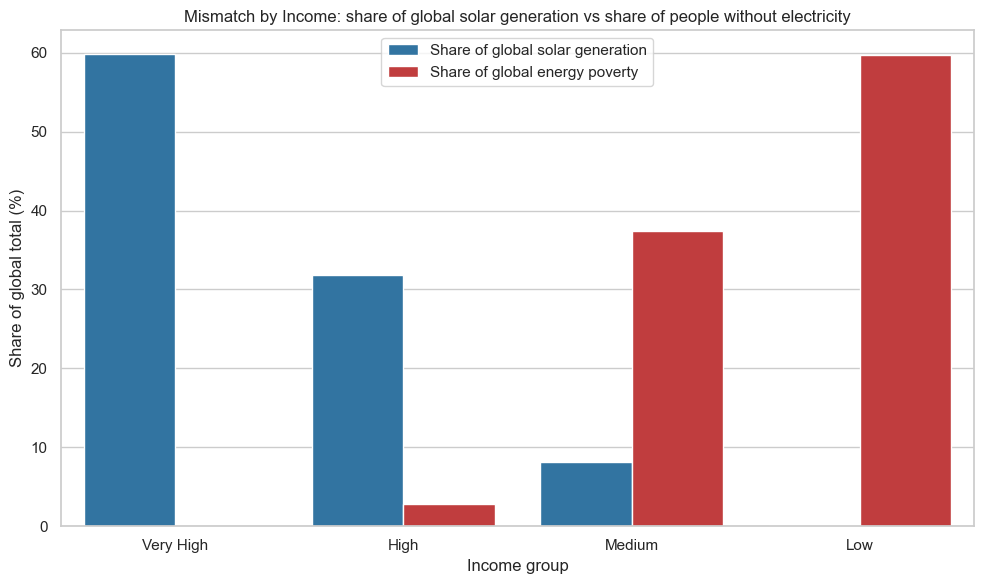

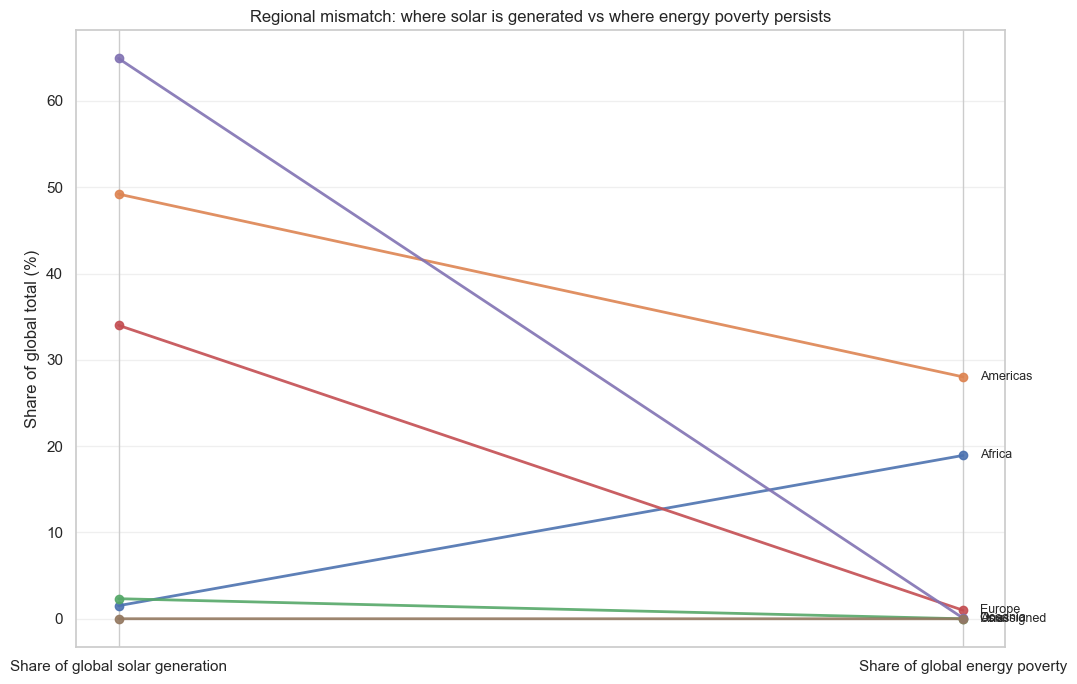

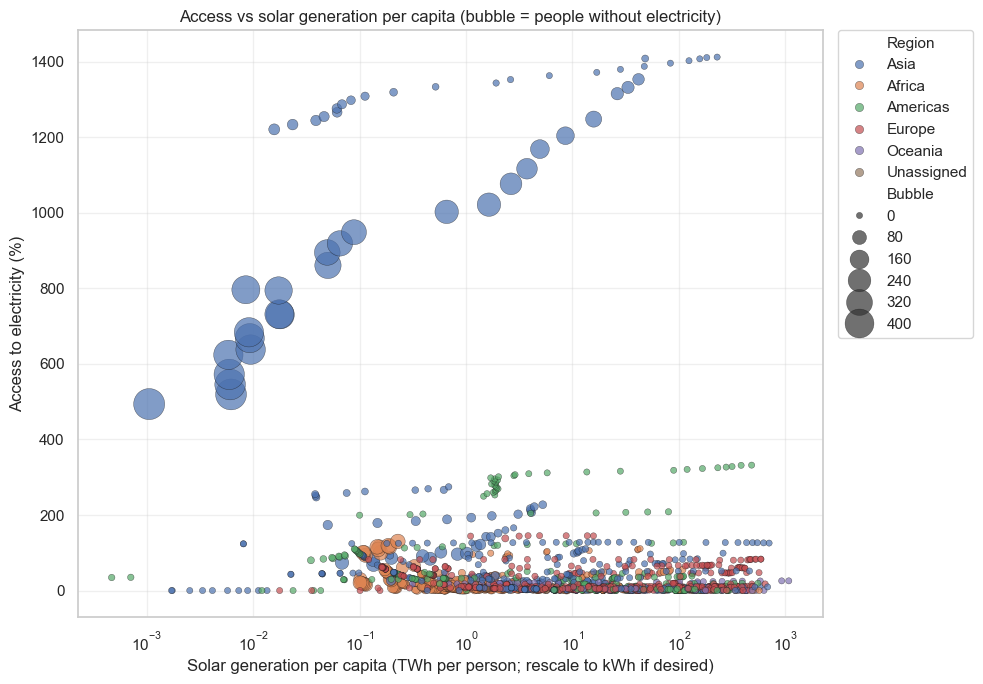

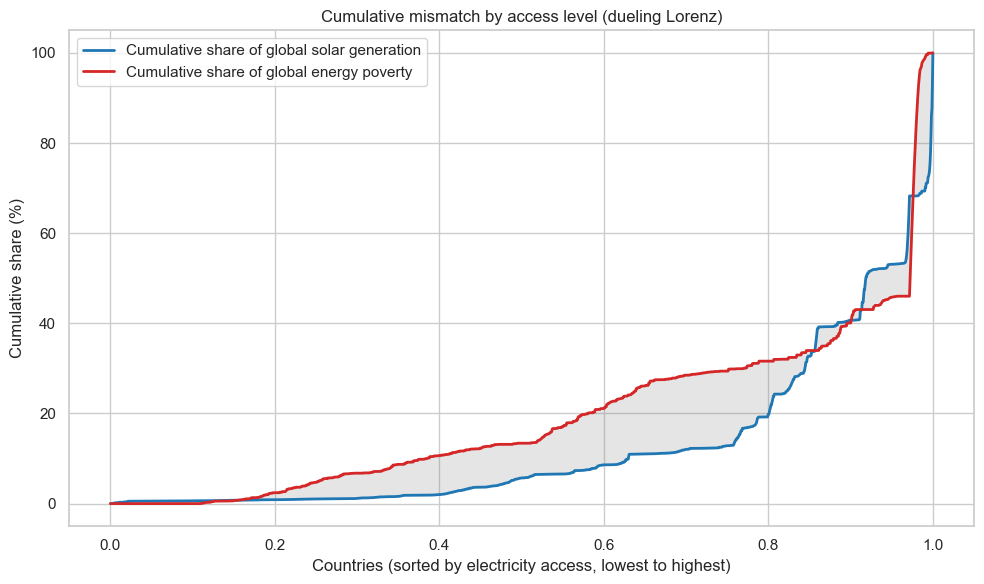

In [93]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

latest = merged_df
pop_clean = df_pop_clean

# Prepare clean fields
latest["Solar_TWh"] = latest["Solar Energy Consumption (TWh)"]

# Drop rows without key fields
latest_hdi = latest.dropna(subset=["Income_Group", "Solar_TWh"])
latest_hdi["People_wo_elec_m"] = latest_hdi["People without electricity (millions)"].fillna(0)

# ------------------------------------------------------------------------------
# 1) HDI mismatch bars: share of global solar vs share of global people without electricity
# ------------------------------------------------------------------------------

hdi_agg = latest_hdi.groupby("Income_Group", as_index=False).agg(
    Solar_TWh=("Solar_TWh", "sum"),
    People_wo_elec_m=("People_wo_elec_m", "sum")
)

tot_solar = hdi_agg["Solar_TWh"].sum()
tot_wo = hdi_agg["People_wo_elec_m"].sum()

hdi_agg["Share_solar_%"] = 100 * hdi_agg["Solar_TWh"] / tot_solar
hdi_agg["Share_wo_%"]    = 100 * hdi_agg["People_wo_elec_m"] / tot_wo

# Order HDI groups for readability
income_group = ["Very High", "High", "Medium", "Low"]
hdi_agg["Income_Group"] = pd.Categorical(hdi_agg["Income_Group"], categories=income_group, ordered=True)
hdi_agg = hdi_agg.sort_values("Income_Group")

# Plot side-by-side bars
hdi_plot = hdi_agg.melt(id_vars="Income_Group", value_vars=["Share_solar_%", "Share_wo_%"],
                        var_name="Metric", value_name="Share (%)")
metric_labels = {"Share_solar_%": "Share of global solar generation", "Share_wo_%": "Share of global energy poverty"}

hdi_plot["Metric"] = hdi_plot["Metric"].map(metric_labels)

plt.figure(figsize=(10,6))
sns.barplot(data=hdi_plot, x="Income_Group", y="Share (%)", hue="Metric", palette=["#1f77b4", "#d62728"])
plt.title("Mismatch by Income: share of global solar generation vs share of people without electricity")
plt.xlabel("Income group"); plt.ylabel("Share of global total (%)")
plt.legend(title="")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 2) Region slope graph: share of solar vs share of energy poverty
# ------------------------------------------------------------------------------

region_agg = latest_hdi.groupby("Region", as_index=False).agg(
    Solar_TWh=("Solar_TWh", "sum"),
    People_wo_elec_m=("People_wo_elec_m", "sum")
)

rtot_solar = region_agg["Solar_TWh"].sum()
rtot_wo = region_agg["People_wo_elec_m"].sum()

region_agg["Share_solar_%"] = 100 * region_agg["Solar_TWh"] / rtot_solar
region_agg["Share_wo_%"]    = 100 * region_agg["People_wo_elec_m"] / rtot_wo

# Build a slope dataframe with two rows per region
region_long = pd.DataFrame({
    "Region": np.repeat(region_agg["Region"].values, 2),
    "Metric": ["Solar generation share", "Energy poverty share"] * len(region_agg),
    "Share (%)": np.hstack([region_agg["Share_solar_%"].values, region_agg["Share_wo_%"].values]),
    "X": np.tile([0, 1], len(region_agg))
})

# Slope plot
plt.figure(figsize=(11,7))
for reg in region_agg["Region"]:
    df_r = region_long[region_long["Region"] == reg].sort_values("X")
    plt.plot(df_r["X"], df_r["Share (%)"], marker="o", linewidth=2, alpha=0.9)
    # Add region label near the right point
    right = df_r.iloc[-1]
    plt.text(1.02, right["Share (%)"], reg, va="center", fontsize=9)

plt.xticks([0,1], ["Share of global solar generation", "Share of global energy poverty"])
plt.title("Regional mismatch: where solar is generated vs where energy poverty persists")
plt.ylabel("Share of global total (%)"); plt.xlabel("")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 3) Country scatter: access vs solar generation per capita (bubble = people without electricity)
# ------------------------------------------------------------------------------


scatter_df = latest.merge(pop_clean, on=["Code","Year"], how="left", suffixes=('', '_pop'))
scatter_df["Solar_TWh_pc"] = (scatter_df["Solar_TWh"] * 1e9) / scatter_df["Population"]  # TWh -> kWh if you prefer
# Keep only countries with both metrics
keep_cols = ["Country","Region","Income_Group","Solar_TWh_pc","People without electricity (millions)","People with electricity (millions)"]
for c in keep_cols:
    if c not in scatter_df.columns:
        scatter_df[c] = np.nan

sd = scatter_df.dropna(subset=["Solar_TWh_pc", "People with electricity (millions)"])
sd["Bubble"] = scatter_df["People without electricity (millions)"].fillna(0)

plt.figure(figsize=(10,7))
ax = sns.scatterplot(
    data=sd,
    x="Solar_TWh_pc",
    y="People with electricity (millions)",
    size="Bubble",
    hue="Region",
    sizes=(20, 500),
    alpha=0.7,
    edgecolor="k",
    linewidth=0.3
)
plt.title("Access vs solar generation per capita (bubble = people without electricity)")
plt.xlabel("Solar generation per capita (TWh per person; rescale to kWh if desired)")
plt.ylabel("Access to electricity (%)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0., title="")
plt.xscale("log")  # per-capita generation varies widely; log clarifies spread
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 4) (Optional) Dueling Lorenz: cumulative solar vs cumulative energy poverty
# ------------------------------------------------------------------------------

dl = latest.copy()
dl = dl.dropna(subset=["Solar_TWh", "People without electricity (millions)", "People with electricity (millions)"])
dl = dl.sort_values("People with electricity (millions)", ascending=True)

dl["cum_solar_share"] = dl["Solar_TWh"].cumsum() / dl["Solar_TWh"].sum()
dl["cum_wo_share"]    = dl["People without electricity (millions)"].cumsum() / dl["People without electricity (millions)"].sum()
dl["cum_pop"] = np.arange(1, len(dl)+1) / len(dl)

plt.figure(figsize=(10,6))
plt.plot(dl["cum_pop"], dl["cum_solar_share"]*100, label="Cumulative share of global solar generation", color="#1f77b4", linewidth=2)
plt.plot(dl["cum_pop"], dl["cum_wo_share"]*100, label="Cumulative share of global energy poverty", color="#d62728", linewidth=2)
plt.fill_between(dl["cum_pop"], dl["cum_solar_share"]*100, dl["cum_wo_share"]*100, color="gray", alpha=0.2)
plt.title("Cumulative mismatch by access level (dueling Lorenz)")
plt.xlabel("Countries (sorted by electricity access, lowest to highest)")
plt.ylabel("Cumulative share (%)")
plt.legend()
plt.tight_layout()
plt.show()

Solar equity analysis displayed as  a strategic simulation and dashboard that shows how interventions like community microleasing could transform solar adoption in underperforming regions.

In [94]:
#Part 1: Annotate Underperforming Regions
#🔍 Identify Underperformers
#This should capture countries with significant infrastructure but low utilization.
#threshold_capacity = merged_df["Installed Solar PV Capacity (GW)"].quantile(0.2)

#This flags countries with low integration of solar into their energy mix, despite capacity.
#threshold_share = merged_df["Solar (% equivalent primary energy)"].quantile(0.1)

# Use more realistic thresholds
threshold_capacity = merged_df["Installed Solar PV Capacity (GW)"].quantile(0.5)   # top 50%
threshold_share = 5  # less than 5% of energy from solar

underperformers = merged_df[
    (merged_df["Installed Solar PV Capacity (GW)"] > threshold_capacity) &
    (merged_df["Solar (% equivalent primary energy)"] < threshold_share) &
    (merged_df["Income_Group"].isin(["Low", "Medium"]))]

underperformers = merged_df[
    (merged_df["Installed Solar PV Capacity (GW)"] > threshold_capacity) &
    (merged_df["Solar (% equivalent primary energy)"] < threshold_share)]

print("Underperformers found:", len(underperformers))
#print(underperformers[["Country", "Installed Solar PV Capacity (GW)", "Solar (% equivalent primary energy)"]].head(20))

fig = px.scatter(
    merged_df,
    x="Installed Solar PV Capacity (GW)",
    y="Solar Energy Consumption (TWh)",
    color="Income_Group",
    hover_name="Country",
    title="Solar Consumption vs Capacity with Underperformers Highlighted"
)

# Add annotations
for country in underperformers["Country"]:
    fig.add_annotation(text=country, x=underperformers.loc[underperformers["Country"] == country, "Installed Solar PV Capacity (GW)"].values[0],
                       y=underperformers.loc[underperformers["Country"] == country, "Solar Energy Consumption (TWh)"].values[0],
                       showarrow=True, arrowhead=1)
fig.show()

#Part 2: Simulate Microleasing Impact
#Assume Microleasing increases solar share by 10–30% in underperforming regions
#It improves efficiency (TWh per MW) by 15–25% due to better utilization

# Simulate impact
solar_boost = 0.3  # 30% increase
efficiency_boost = 0.25  # 25% increase

underperformers["Simulated Solar Share (%)"] = underperformers["Solar (% equivalent primary energy)"] * solar_boost
underperformers["Simulated Efficiency"] = underperformers["Efficiency_TWh_per_MW"] * efficiency_boost

fig.update_layout(yaxis=dict(range=[0, 5]))  # Adjust based on your data

#Part 3: Solar Justice KPI Dashboard
#Key Metrics to Track
#Solar Share (%)
#Installed Capacity (MW)
#Efficiency (TWh/MW)
#HDI Group
#Simulated Solar Share
#Simulated Efficiency

kpi_df = underperformers[[
    "Country", "Income_Group", "Installed Solar PV Capacity (GW)",
    "Solar (% equivalent primary energy)", "Efficiency_TWh_per_MW",
    "Simulated Solar Share (%)", "Simulated Efficiency"
]]

kpi_df = kpi_df.sort_values("Solar (% equivalent primary energy)", ascending=True)
kpi_df["Solar Share Δ (%)"] = kpi_df["Simulated Solar Share (%)"] - kpi_df["Solar (% equivalent primary energy)"]
kpi_df["Efficiency Δ"] = kpi_df["Simulated Efficiency"] - kpi_df["Efficiency_TWh_per_MW"]

fig = px.bar(
    kpi_df,
    x="Income_Group",
    y=["Solar (% equivalent primary energy)", "Simulated Solar Share (%)"],
    barmode="group",
    title="Solar Share Before and After Microleasing Simulation"
)
fig.update_layout(yaxis=dict(range=[0, 5]))  # Adjust based on your data
fig.show()

fig2 = px.bar(
    underperformers,
    x="Income_Group",
    y=["Efficiency_TWh_per_MW", "Simulated Efficiency"],
    barmode="group",
    title="Efficiency Before and After Microleasing Simulation"
)
fig2.update_layout(yaxis_title="Efficiency (TWh/MW)", xaxis_title="Country")
fig2.show()



Underperformers found: 852


C:\Users\anuna\AppData\Local\Temp\ipykernel_2276\2283722286.py:49: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\anuna\AppData\Local\Temp\ipykernel_2276\2283722286.py:50: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



Visualizing Solar Equity Flows by HDI Group using a Sankey diagram

In [95]:
# 📦 Step 1: Install & Import Libraries
import pandas as pd
import plotly.graph_objects as go

# 🧭 Step 3: Define Nodes
nodes = [
    "Installed Capacity", "Solar Share", "Solar Consumption",
    "Very High HDI", "High HDI", "Medium HDI", "Low HDI"
]
node_indices = {name: i for i, name in enumerate(nodes)}

# 🔗 Step 4: Create Flows
links = {
    'source': [],
    'target': [],
    'value': [],
    'label': []
}

# Capacity → Share
for _, row in merged_df.iterrows():
    links['source'].append(node_indices["Installed Capacity"])
    links['target'].append(node_indices["Solar Share"])
    links['value'].append(row['Installed Solar PV Capacity (GW)'])
    links['label'].append(f"{row['Income_Group']} Capacity")

# Share → Consumption
for _, row in merged_df.iterrows():
    links['source'].append(node_indices["Solar Share"])
    links['target'].append(node_indices["Solar Consumption"])
    links['value'].append(row['Solar (% equivalent primary energy)'])
    links['label'].append(f"{row['Income_Group']} Share")

# Consumption → HDI Group
for _, row in merged_df.iterrows():
    links['source'].append(node_indices["Solar Consumption"])
    links['target'].append(node_indices[f"{row['Income_Group']} HDI"])
    links['value'].append(row['Solar Energy Consumption (TWh)'])
    links['label'].append(f"{row['Income_Group']} Consumption")

# 🎨 Step 5: Build Sankey Diagram
fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=15,
        thickness=20,
        line=dict(color="black", width=0.5),
        label=nodes,
        color="lightblue"
    ),
    link=dict(
        source=links['source'],
        target=links['target'],
        value=links['value'],
        label=links['label']
    )
)])

fig.update_layout(title_text="Solar Energy Flow by HDI Group", font_size=12)
fig.show()

# 📦 Step 1: Import Libraries
import pandas as pd
import plotly.graph_objects as go

# 📊 Step 2: Aggregate Data by Income Group
solar_df = merged_df.groupby('Income_Group').agg({
    'Installed Solar PV Capacity (GW)': 'sum',
    'Solar (% equivalent primary energy)': 'mean',
    'Solar Energy Consumption (TWh)': 'sum'
}).reset_index()

# 🧭 Step 3: Define Nodes
nodes = [
    "Installed Capacity", "Solar Share", "Solar Consumption",
    "Very High", "High", "Medium", "Low"
]
node_indices = {name: i for i, name in enumerate(nodes)}

# 🔗 Step 4: Create Flows
links = {'source': [], 'target': [], 'value': [], 'label': []}

# Capacity → Share
for _, row in solar_df.iterrows():
    links['source'].append(node_indices["Installed Capacity"])
    links['target'].append(node_indices["Solar Share"])
    links['value'].append(row["Installed Solar PV Capacity (GW)"])
    links['label'].append(f"{row['Income_Group']} Capacity")

# Share → Consumption
for _, row in solar_df.iterrows():
    links['source'].append(node_indices["Solar Share"])
    links['target'].append(node_indices["Solar Consumption"])
    links['value'].append(row["Solar (% equivalent primary energy)"])
    links['label'].append(f"{row['Income_Group']} Share")

# Consumption → HDI Group
for _, row in solar_df.iterrows():
    links['source'].append(node_indices["Solar Consumption"])
    links['target'].append(node_indices[f"{row['Income_Group']}"])
    links['value'].append(row["Solar Energy Consumption (TWh)"])
    links['label'].append(f"{row['Income_Group']} Consumption")

# 🎨 Step 5: Build Sankey Diagram
fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=15,
        thickness=20,
        line=dict(color="black", width=0.5),
        label=nodes,
        color="lightblue"
    ),
    link=dict(
        source=links['source'],
        target=links['target'],
        value=links['value'],
        label=links['label']
    )
)])

fig.update_layout(title_text="Solar Energy Flow by Income Group", font_size=12)
fig.show()

# 📦 Step 1: Import Libraries
import pandas as pd
import plotly.graph_objects as go

# 📊 Step 2: Calculate Efficiency
merged_df = merged_df[merged_df["Installed Solar PV Capacity (GW)"] > 0]
merged_df["Efficiency_TWh_per_MW"] = merged_df["Solar Energy Consumption (TWh)"] / merged_df["Installed Solar PV Capacity (GW)"]

# 🔍 Step 3: Identify Underperformers
threshold_capacity = merged_df["Installed Solar PV Capacity (GW)"].quantile(0.5)
threshold_share = merged_df["Solar (% equivalent primary energy)"].quantile(0.4)
underperformers = merged_df[
    (merged_df["Installed Solar PV Capacity (GW)"] > threshold_capacity) &
    (merged_df["Solar (% equivalent primary energy)"] < threshold_share)
]

# 🔧 Step 4: Simulate Microleasing Impact
solar_boost = 1.3  # +30% share
efficiency_boost = 1.25  # +25% efficiency
underperformers["Simulated Solar Share (%)"] = underperformers["Solar (% equivalent primary energy)"] * solar_boost
underperformers["Simulated Efficiency"] = underperformers["Efficiency_TWh_per_MW"] * efficiency_boost

# 🧭 Step 5: Define Nodes
nodes = [
    "Installed Capacity", "Solar Share", "Solar Consumption",
    "Simulated Share", "Simulated Consumption",
    "Very High", "High", "Medium", "Low"
]
node_indices = {name: i for i, name in enumerate(nodes)}

# 🔗 Step 6: Create Flows
links = {'source': [], 'target': [], 'value': [], 'label': []}

# Actual Flows
for _, row in underperformers.iterrows():
    hdi = row["Income_Group"]
    links['source'].append(node_indices["Installed Capacity"])
    links['target'].append(node_indices["Solar Share"])
    links['value'].append(row["Installed Solar PV Capacity (GW)"])
    links['label'].append(f"{row['Country']} Actual Capacity")

    links['source'].append(node_indices["Solar Share"])
    links['target'].append(node_indices["Solar Consumption"])
    links['value'].append(row["Solar (% equivalent primary energy)"])
    links['label'].append(f"{row['Country']} Actual Share")

    links['source'].append(node_indices["Solar Consumption"])
    links['target'].append(node_indices[f"{hdi}"])
    links['value'].append(row["Solar Energy Consumption (TWh)"])
    links['label'].append(f"{row['Country']} Actual Consumption")

# Simulated Flows
for _, row in underperformers.iterrows():
    hdi = row["Income_Group"]
    links['source'].append(node_indices["Installed Capacity"])
    links['target'].append(node_indices["Simulated Share"])
    links['value'].append(row["Installed Solar PV Capacity (GW)"])
    links['label'].append(f"{row['Country']} Simulated Capacity")

    links['source'].append(node_indices["Simulated Share"])
    links['target'].append(node_indices["Simulated Consumption"])
    links['value'].append(row["Simulated Solar Share (%)"])
    links['label'].append(f"{row['Country']} Simulated Share")

    links['source'].append(node_indices["Simulated Consumption"])
    links['target'].append(node_indices[f"{hdi}"])
    links['value'].append(row["Simulated Efficiency"] * row["Installed Solar PV Capacity (GW)"])
    links['label'].append(f"{row['Country']} Simulated Consumption")

# 🎨 Step 7: Build Sankey Diagram
fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=15,
        thickness=20,
        line=dict(color="black", width=0.5),
        label=nodes,
        color="lightblue"
    ),
    link=dict(
        source=links['source'],
        target=links['target'],
        value=links['value'],
        label=links['label']
    )
)])

fig.update_layout(title_text="Solar Equity Flow: Actual vs Simulated Microleasing Impact", font_size=12)
fig.show()



C:\Users\anuna\AppData\Local\Temp\ipykernel_2276\1196786697.py:142: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\anuna\AppData\Local\Temp\ipykernel_2276\1196786697.py:143: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [ ]:
#Chloropeths
import geopandas as gpd
import requests
import zipfile
import io
import os
import shutil
# Load the dataset
df = merged_df
# Filter for 2021
waste_df = merged_df[merged_df['Income_Group'] == 'Low']
#waste_df = merged_df[merged_df['Year'] == '2021']
waste_df = waste_df.rename(columns={'Country_code_A3': 'iso_a3'})
waste_df['Number of people without electricity'] = waste_df['Number of people without electricity'].astype(float)
# Exclude non-country entries (e.g., Int. Aviation, Int. Shipping)
# Load world map shapefile
# Try downloading Natural Earth 1:110m cultural vectors
url = 'https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip'
shapefile_dir = 'ne_110m_admin_0_countries'
# Download and extract shapefile
headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36'}
response = requests.get(url, headers=headers)
response.raise_for_status()
# Extract zip file
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    z.extractall(shapefile_dir)
# Load shapefile
world = gpd.read_file(shapefile_dir)
# Merge emissions data with world map
world = world.merge(waste_df[['Country_code_A3', 'Number of people without electricity', 'Country']], left_on='SOV_A3', right_on='Country_code_A3', how='left')

# Handle missing data
world['Number of people without electricity'] = world['Number of people without electricity'].fillna(0)  # Set missing emissions to 0 for visualization
print("Countries with missing Waste emissions data:", world[world['Number of people without electricity'].isna()]['SOVEREIGNT'].tolist())
# Create choropleth map
fig, ax = plt.subplots(figsize=(15, 10))
# Use logarithmic scale for better visualization due to wide range of emissions
world['Emissions_log'] = np.log1p(world['Number of people without electricity'])  # log(1 + x) to handle zero values
world.plot(
    column='Emissions_log',
    ax=ax,
    legend=True,
    cmap='plasma',
    legend_kwds={
        'label': "Waste Emissions (log kt CO2eq, 2023)",
        'orientation': "horizontal",
        'shrink': 0.6
    },
    missing_kwds={'color': 'lightgrey', 'label': 'No Data'}
)
# Customize the plot
plt.title('Global Landbased Emissions from Food Systems (2023)', fontsize=16)
ax.set_axis_off()
# Add annotations for top 5 emitting countries
top_5 = world.nlargest(5, 'Number of people without electricity')[['Name', 'Number of people without electricity', 'geometry']]
for idx, row in top_5.iterrows():
    centroid = row['geometry'].centroid
    ax.annotate(
        f"{row['Name']} ({row['Number of people without electricity']:.0f} kt)",
        xy=(centroid.x, centroid.y),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='none')
    )

KeyError: ('Code', 'Country')